# 03 - CatBoost: Optuna tuning, evaluation and MLflow tracking

**Goal:** tune CatBoost with Optuna, train the best configuration, and evaluate it on the untouched test set - with and without `redshift` - while tracking everything in MLflow.

**CatBoost** is a gradient-boosting library from Yandex that builds *symmetric (oblivious) decision trees*: every level of a tree uses the same split on all its nodes. This makes each tree a strong regulariser and fast at inference; it also uses *ordered boosting* to reduce overfitting.

## Protocol (the same for both models, so the comparison is fair)
1. **Same data**: identical train / validation / test rows; same two feature configurations (with / without `redshift`).
2. **Optuna** (TPE sampler, fixed seed) searches the hyper-parameters. **Objective = Macro-F1 on the validation set.**
   The test set is not touched here. Inside each trial the number of trees is chosen by early stopping on the validation set.
3. The best parameters are used to fit the **final model** on the training set.
4. **Only then** is the finished model scored once on the test set (metrics, confusion matrix) - these numbers are stored and compared in notebook 05.
5. **MLflow** records everything: one *parent run* per (model, feature configuration) holding settings, best parameters, metrics, timings, plots, the saved model, and one *nested child run per Optuna trial*.

## 1. Setup and settings

In [1]:
import sys, warnings, json
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")          # shared helpers live in src/common.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
from common import (ROOT, ART, SEED, CLASSES, MAGS, COLORS, ID_COLS, SKY_COLS, FEATURE_SETS, PALETTE,
                    load_raw, clean, add_color_indices, make_splits, mlflow_experiment)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 140)

import time, joblib, optuna
from sklearn.metrics import f1_score, classification_report
from common import compute_metrics, conf_mat, plot_cm, plot_history, plot_param_importance, plot_feature_importance
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ---- experiment settings ---------------------------------------------------------------------------------------
N_TRIALS     = 20      # Optuna trials per model WITH redshift (main experiment)
N_TRIALS_NOZ = 10      # Optuna trials per model WITHOUT redshift (ablation)
MAX_ITERS    = 800     # upper bound on boosting rounds; early stopping on the validation set picks the real number
ES_ROUNDS    = 40      # stop when the validation loss has not improved for 40 rounds
CMP = ART / "comparison"; MODELS_DIR = ART / "models"
CMP.mkdir(parents=True, exist_ok=True); MODELS_DIR.mkdir(parents=True, exist_ok=True)

## 2. Data
The split is rebuilt from `src/common.py`; features are the nine photometric columns (+ `redshift` in the main configuration).

In [2]:
df, _ = clean(load_raw())
S = make_splits(df)                      # identical stratified 70/15/15 split in every notebook (seed 42)
print({k: v.shape for k, v in S.items()})
print("validation class shares (%):", S["val"]["class"].value_counts(normalize=True).mul(100).round(1).to_dict())

{'train': (69999, 23), 'val': (15000, 23), 'test': (15000, 23)}
validation class shares (%): {'GALAXY': 59.4, 'STAR': 21.6, 'QSO': 19.0}


## 3. Hyper-parameter search space
| Parameter | Range | Role |
|---|---|---|
| `learning_rate` | 0.03 - 0.3 (log) | step size; low = slower but smoother |
| `depth` | 4 - 9 | tree depth (complexity) |
| `l2_leaf_reg` | 1 - 20 (log) | L2 regularisation of leaf values |
| `random_strength` | 1e-3 - 10 (log) | randomness added when scoring splits |
| `bagging_temperature` | 0 - 1 | intensity of Bayesian bootstrap sampling |
| `border_count` | 64 / 128 / 254 | number of bins for numeric features |
| `auto_class_weights` | None / Balanced | re-weight classes to counter imbalance |

In [3]:
ALGO, EXPERIMENT = "catboost", "SDSS17-CatBoost"

def suggest(trial):
    return {
            "learning_rate": trial.suggest_float("learning_rate", 0.03, 0.3, log=True),
            "depth": trial.suggest_int("depth", 4, 9),
            "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0, log=True),
            "random_strength": trial.suggest_float("random_strength", 1e-3, 10.0, log=True),
            "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 1.0),
            "border_count": trial.suggest_categorical("border_count", [64, 128, 254]),
            "auto_class_weights": trial.suggest_categorical("auto_class_weights", ["None", "Balanced"])
        }

## 4. Building and fitting the model
`build` creates a model from a parameter dictionary and `fit` trains it with **early stopping on the validation set**, returning the number of trees actually used.
(The string `"None"` is used for "no class weighting" because Optuna categorical choices should be simple types.)

In [4]:
import mlflow.catboost
from catboost import CatBoostClassifier


def build(params):
    p = dict(params)
    p["auto_class_weights"] = None if p.get("auto_class_weights") == "None" else p.get("auto_class_weights")
    return CatBoostClassifier(loss_function="MultiClass", eval_metric="MultiClass", iterations=MAX_ITERS, random_seed=SEED,
                              verbose=0, allow_writing_files=False, early_stopping_rounds=ES_ROUNDS, **p)

def fit(model, Xtr, ytr, Xva, yva):
    model.fit(Xtr, ytr, eval_set=(Xva, yva))               # early stopping + best-iteration selection on VALIDATION loss
    return int(model.get_best_iteration() or 0) + 1

def feature_importance(model, feats):
    imp = pd.Series(model.get_feature_importance(), index=feats)
    return (imp / imp.sum()).sort_values(ascending=False)

## 5. One full experiment: Optuna study -> final model -> test evaluation -> MLflow
`run_experiment(cfg, n_trials)` does the whole protocol for one feature configuration:

* **objective(trial):** suggest parameters -> fit -> compute **validation Macro-F1** -> log the trial as a nested MLflow run -> return the score to Optuna.
* After the study: save the trial table and plots, refit the best parameters, evaluate on validation and (once) on test, save the confusion matrix, feature importances and the model, and log everything.

In [5]:
def run_experiment(cfg, n_trials):
    feats = FEATURE_SETS[cfg]
    Xtr, ytr = S["train"][feats], S["train"]["y"].values
    Xva, yva = S["val"][feats], S["val"]["y"].values
    Xte, yte = S["test"][feats], S["test"]["y"].values
    tag = f"{cfg}_{ALGO}"
    out = CMP / tag; out.mkdir(parents=True, exist_ok=True)
    mlflow_experiment(EXPERIMENT)

    with mlflow.start_run(run_name=f"{tag}_optuna") as parent:
        mlflow.set_tags({"algorithm": ALGO, "feature_config": cfg, "stage": "optimization+evaluation"})
        mlflow.log_params({"n_trials": n_trials, "sampler": "TPE", "objective": "validation macro F1",
                           "features": ",".join(feats), "max_iterations": MAX_ITERS, "early_stopping_rounds": ES_ROUNDS,
                           "split": "70/15/15 stratified", "seed": SEED}
                          )

        # ---------- 1) Optuna study: objective uses ONLY train + validation
        def objective(trial):
            params = suggest(trial)
            m = build(params)
            t = time.time()
            it = fit(m, Xtr, ytr, Xva, yva)
            f1 = f1_score(yva, np.asarray(m.predict(Xva)).ravel().astype(int), average="macro")      # validation Macro-F1
            trial.set_user_attr("best_iteration", it)
            trial.set_user_attr("seconds", time.time() - t)
            with mlflow.start_run(run_name=f"trial_{trial.number:03d}", nested=True):                  # one child run per trial
                mlflow.log_params({k: str(v) for k, v in params.items()})
                mlflow.log_metrics({"val_macro_f1": f1, "best_iteration": it, "train_seconds": time.time() - t})
            return f1


        t0 = time.time()
        study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name=tag)
        study.optimize(objective, n_trials=n_trials)
        opt_seconds = time.time() - t0
        tdf = study.trials_dataframe()
        tdf.to_csv(out / "optuna_trials.csv", index=False)
        print(f"[{tag}] best validation Macro-F1 = {study.best_value:.4f} after {n_trials} trials ({opt_seconds:.0f}s)")
        print("best params:", study.best_params)

        plot_history(tdf, f"Optuna - {ALGO} ({cfg})", out / "optuna_history.png")
        pimp = plot_param_importance(study, f"Hyper-parameter importance - {ALGO}", out / "optuna_param_importance.png")
        mlflow.log_metrics({"optuna_best_val_macro_f1": study.best_value, "optuna_seconds": opt_seconds})
        mlflow.log_params({f"best_{k}": v for k, v in study.best_params.items()})

        # ---------- 2) final model = best params, fitted on TRAIN (early stopping on val)
        best = study.best_params
        model = build(best)
        t = time.time()
        it = fit(model, Xtr, ytr, Xva, yva)
        fit_secs = time.time() - t

        # ---------- 3) evaluation: validation, then the test set ONCE
        pv = np.asarray(model.predict(Xva)).ravel().astype(int)
        t = time.time(); pt = np.asarray(model.predict(Xte)).ravel().astype(int); pred_secs = time.time() - t
        mv, mt = compute_metrics(yva, pv), compute_metrics(yte, pt)
        cm = conf_mat(yte, pt)
        plot_cm(cm, f"{ALGO} ({cfg}) - test", out / "confusion_matrix_test.png")
        rep = classification_report(yte, pt, target_names=CLASSES, output_dict=True)
        imp = feature_importance(model, feats)
        plot_feature_importance(imp, f"Feature importance - {ALGO} ({cfg})", out / "feature_importance.png")

        res = {"config": cfg, "model": ALGO, "features": feats, "best_params": best, "best_iteration": it, "val": mv, "test": mt,
               "confusion_matrix_test": cm.tolist(), "classification_report_test": rep, "feature_importance": imp.round(5).to_dict(),
               "optuna_param_importance": pimp, "optuna_best_val_macro_f1": study.best_value, "optuna_seconds": opt_seconds,
               "final_fit_seconds": fit_secs, "predict_seconds_test": pred_secs, "n_trials": n_trials}
        (out / "result.json").write_text(json.dumps(res, indent=2))

        # ---------- 4) MLflow: metrics, artifacts (plots/tables) and the model itself; local copy for the Streamlit app
        mlflow.log_metrics({**{f"val_{k}": v for k, v in mv.items()}, **{f"test_{k}": v for k, v in mt.items()}})
        mlflow.log_metrics({"final_fit_seconds": fit_secs, "predict_seconds_test": pred_secs, "best_iteration": it})
        mlflow.log_artifacts(str(out), artifact_path="evaluation")

        model.save_model(str(MODELS_DIR / f"{tag}.cbm"))                 # local copy used by the Streamlit app
        mlflow.catboost.log_model(model, name="model")                     # model artifact inside the MLflow run

    return res

## 6. Run the main experiment - with redshift
_Main experiment: this is the CatBoost model that competes in the final selection._

[with_redshift_catboost] best validation Macro-F1 = 0.9742 after 20 trials (676s)
best params: {'learning_rate': 0.04996922623114375, 'depth': 9, 'l2_leaf_reg': 1.4277767021954086, 'random_strength': 0.00540597105428018, 'bagging_temperature': 0.44687077683191534, 'border_count': 254, 'auto_class_weights': 'None'}


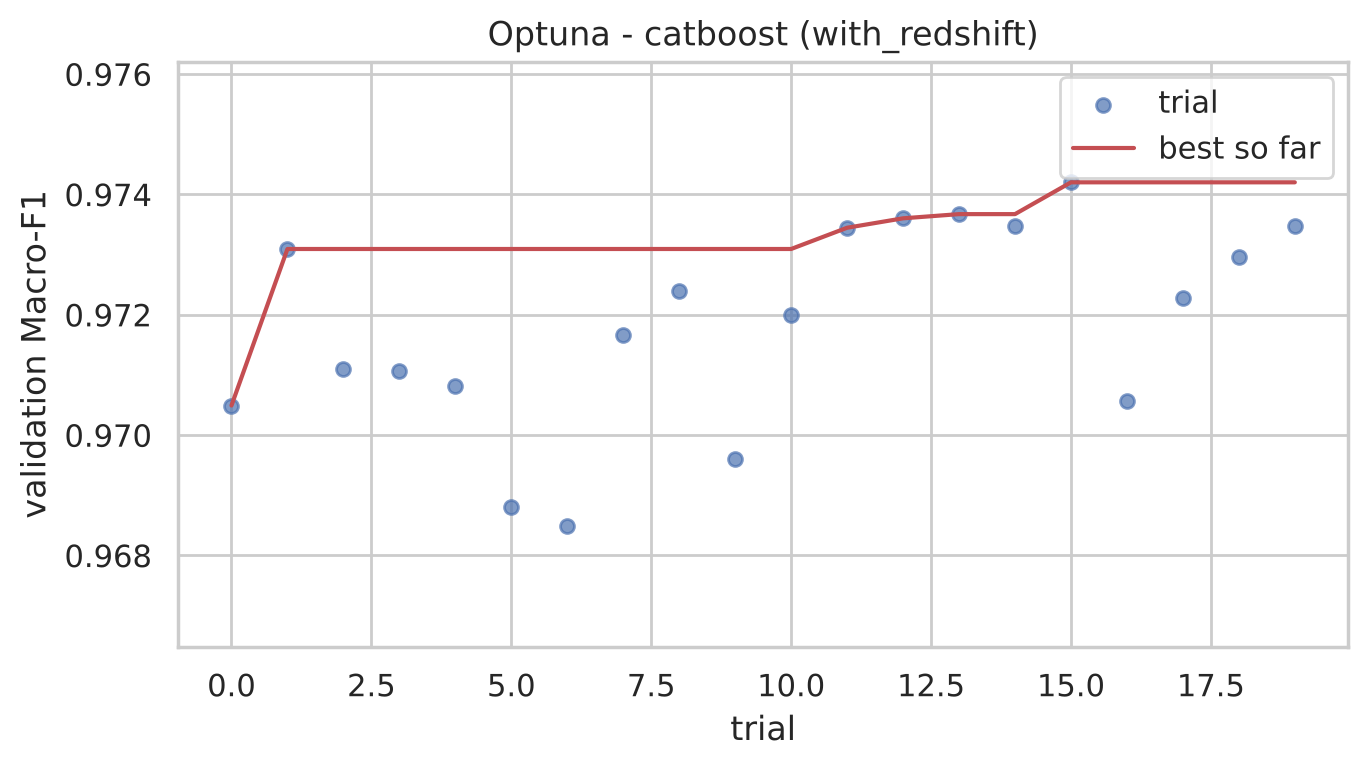

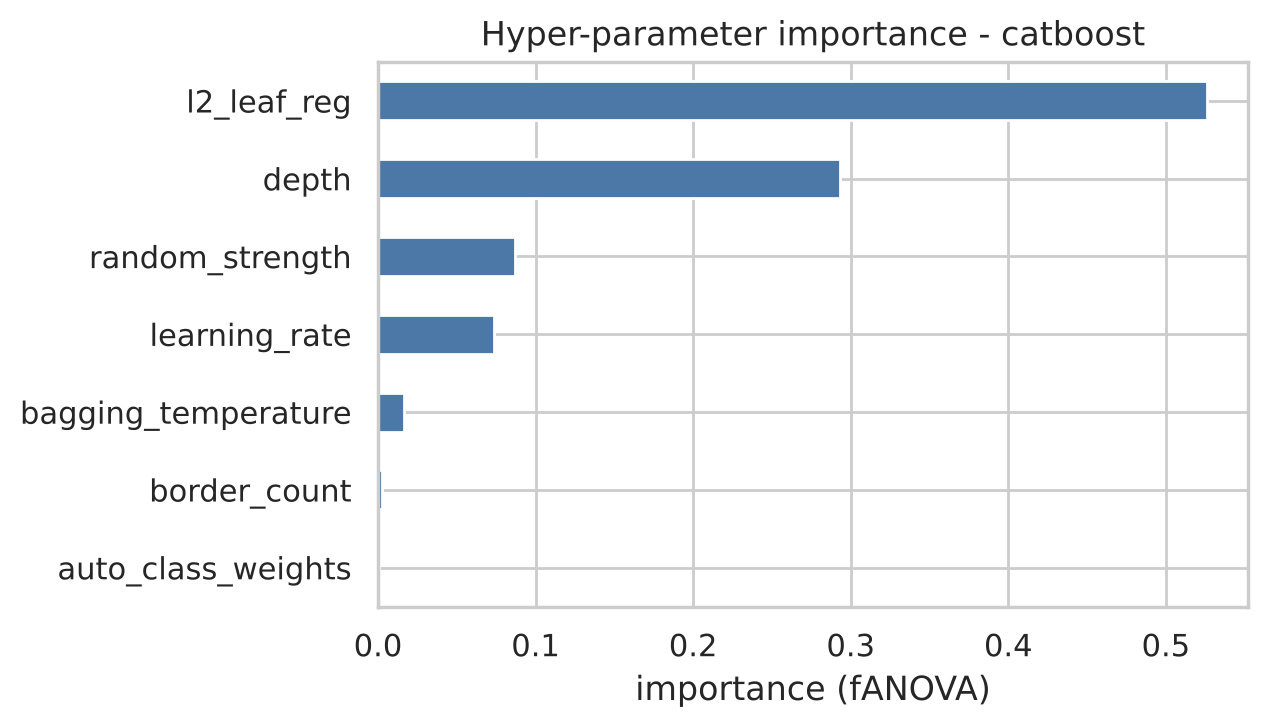

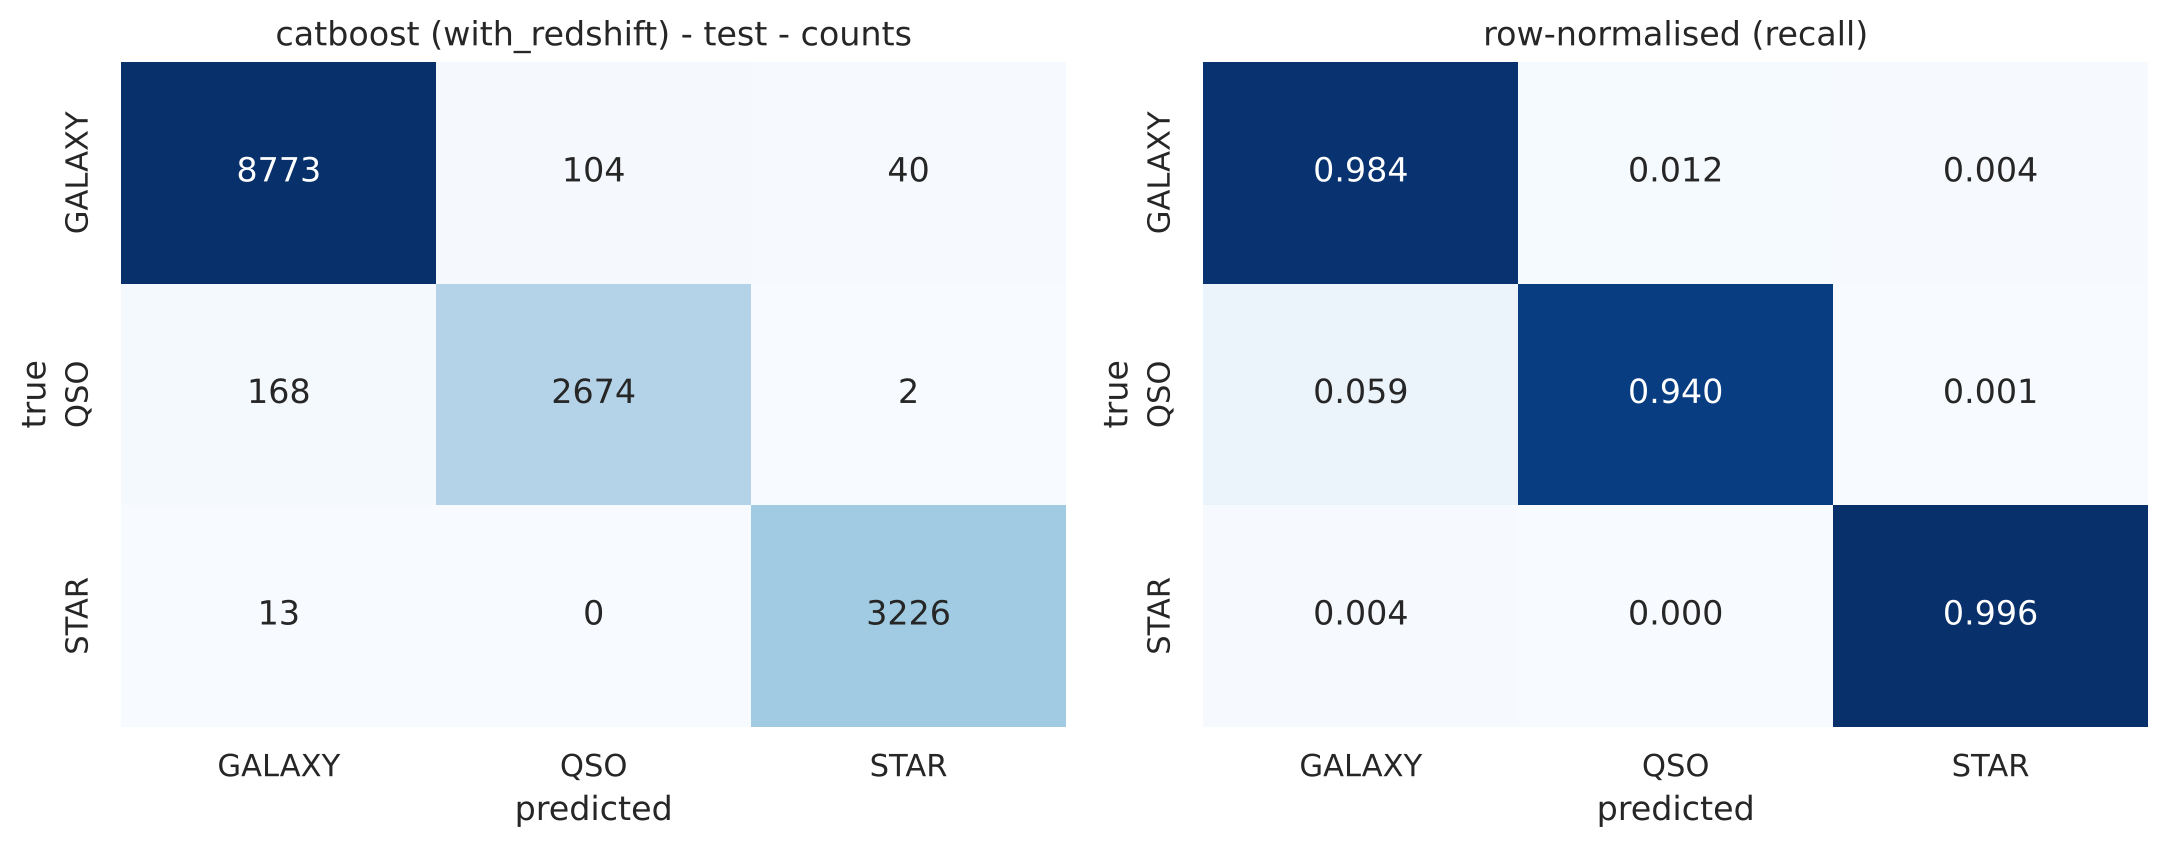

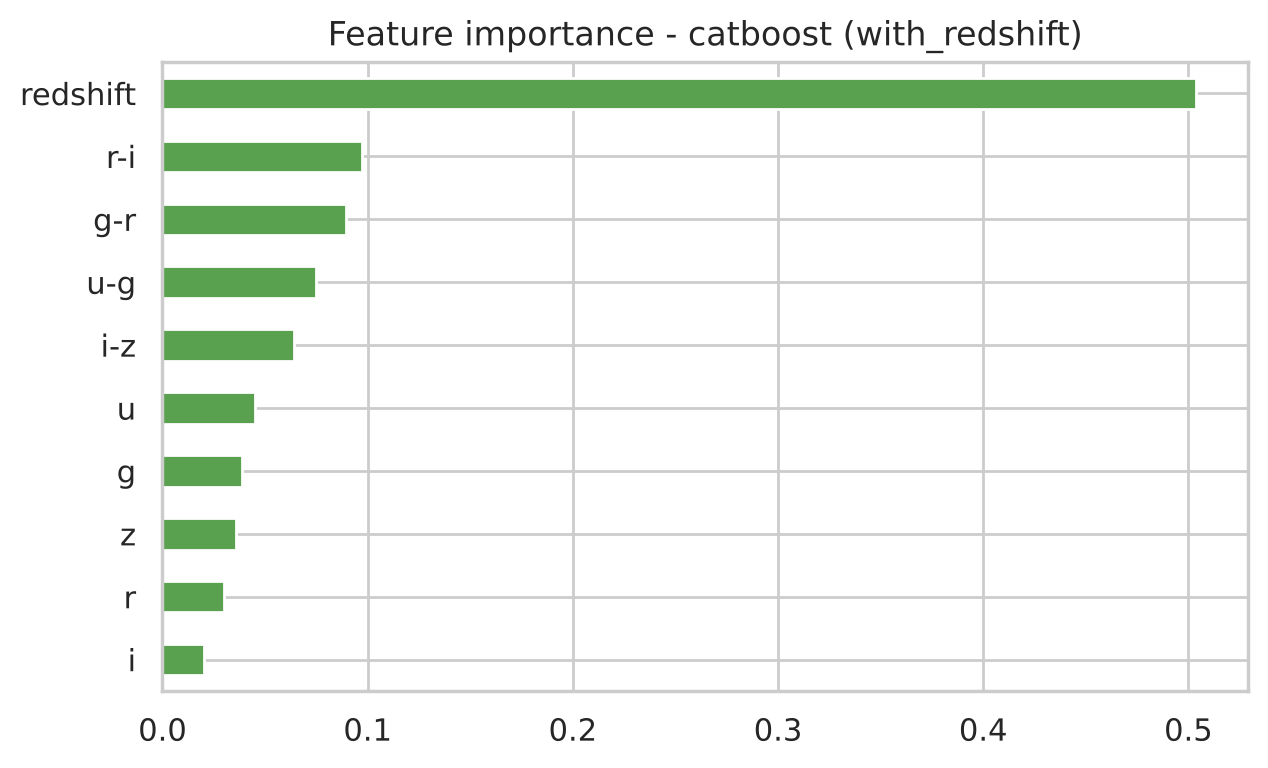


validation: {'accuracy': 0.9777, 'macro_f1': 0.9742, 'weighted_f1': 0.9776}
test      : {'accuracy': 0.9782, 'macro_f1': 0.9749, 'weighted_f1': 0.9781}


In [6]:
res_z = run_experiment("with_redshift", N_TRIALS)
print()
print("validation:", {k: round(v, 4) for k, v in res_z["val"].items() if k in ("accuracy", "macro_f1", "weighted_f1")})
print("test      :", {k: round(v, 4) for k, v in res_z["test"].items() if k in ("accuracy", "macro_f1", "weighted_f1")})

**What to look at:** the optimisation-history plot (best-so-far line rising and flattening shows the search converging), the hyper-parameter importance plot (which knobs actually mattered), and the confusion matrix (where the model still makes mistakes). Test numbers are *reported only* - they were not used to choose anything.

In [7]:
display(pd.DataFrame(res_z["classification_report_test"]).T.round(4))
display(pd.Series(res_z["feature_importance"]).to_frame("importance").T.round(3))

,precision,recall,f1-score,support
GALAXY,0.9798,0.9839,0.9818,8917.0000
QSO,0.9626,0.9402,0.9513,2844.0000
STAR,0.9871,0.9960,0.9915,3239.0000
accuracy,0.9782,0.9782,0.9782,0.9782
macro avg,0.9765,0.9734,0.9749,15000.0000
weighted avg,0.9781,0.9782,0.9781,15000.0000


,redshift,r-i,g-r,u-g,i-z,u,g,z,r,i
importance,0.504,0.097,0.09,0.075,0.064,0.045,0.039,0.036,0.03,0.02


**Reading the result:** CatBoost reaches a Macro-F1 near 0.975 on the test set. The confusion matrix shows most errors (83 %) are between **QSO and GALAXY** (quasars are the hardest class: F1 ~0.95 versus ~0.99 for stars). `redshift` carries the bulk of the feature importance, followed by the colours `r-i`/`g-r`/`u-g`.

## 7. Ablation - without redshift
The same protocol with the photometry-only features (fewer trials because the ablation is a secondary experiment). This quantifies how much of the performance depends on redshift.

[without_redshift_catboost] best validation Macro-F1 = 0.8518 after 10 trials (247s)
best params: {'learning_rate': 0.21888937469133463, 'depth': 7, 'l2_leaf_reg': 2.694686557241768, 'random_strength': 0.0017956984225677636, 'bagging_temperature': 0.3109823217156622, 'border_count': 128, 'auto_class_weights': 'None'}


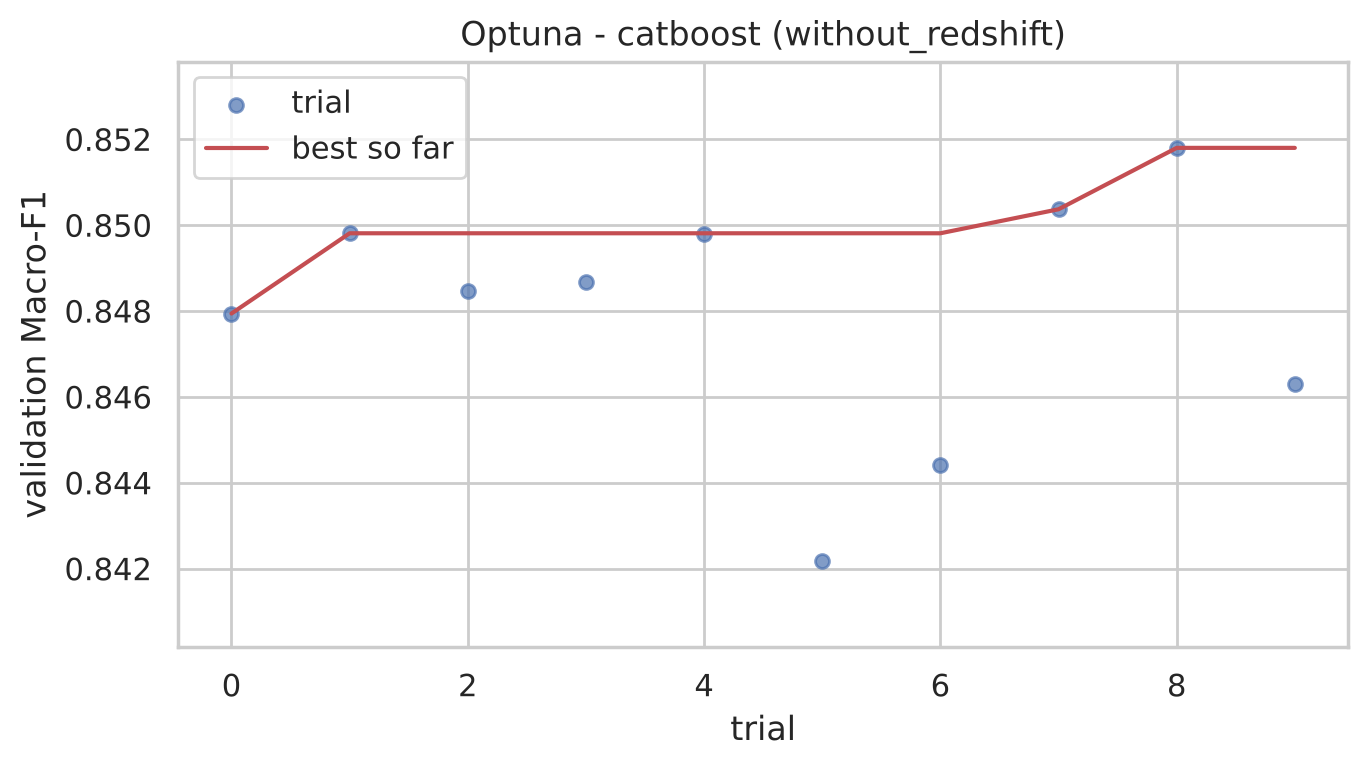

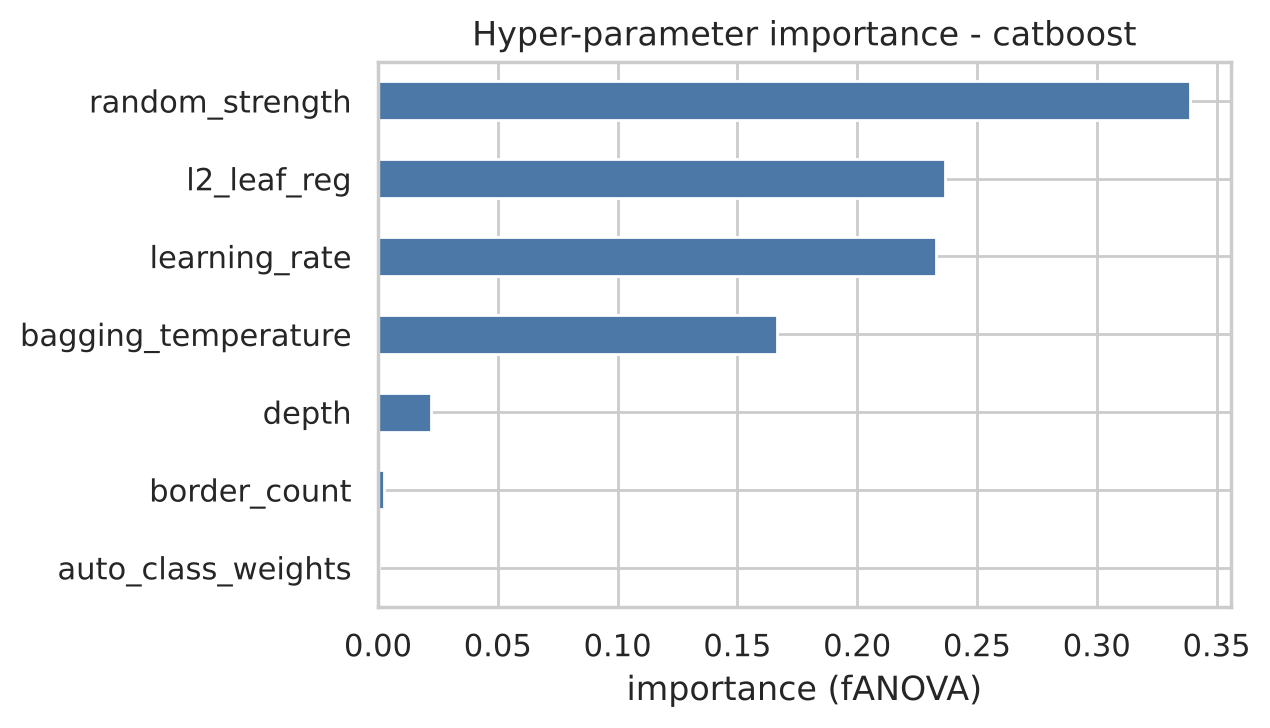

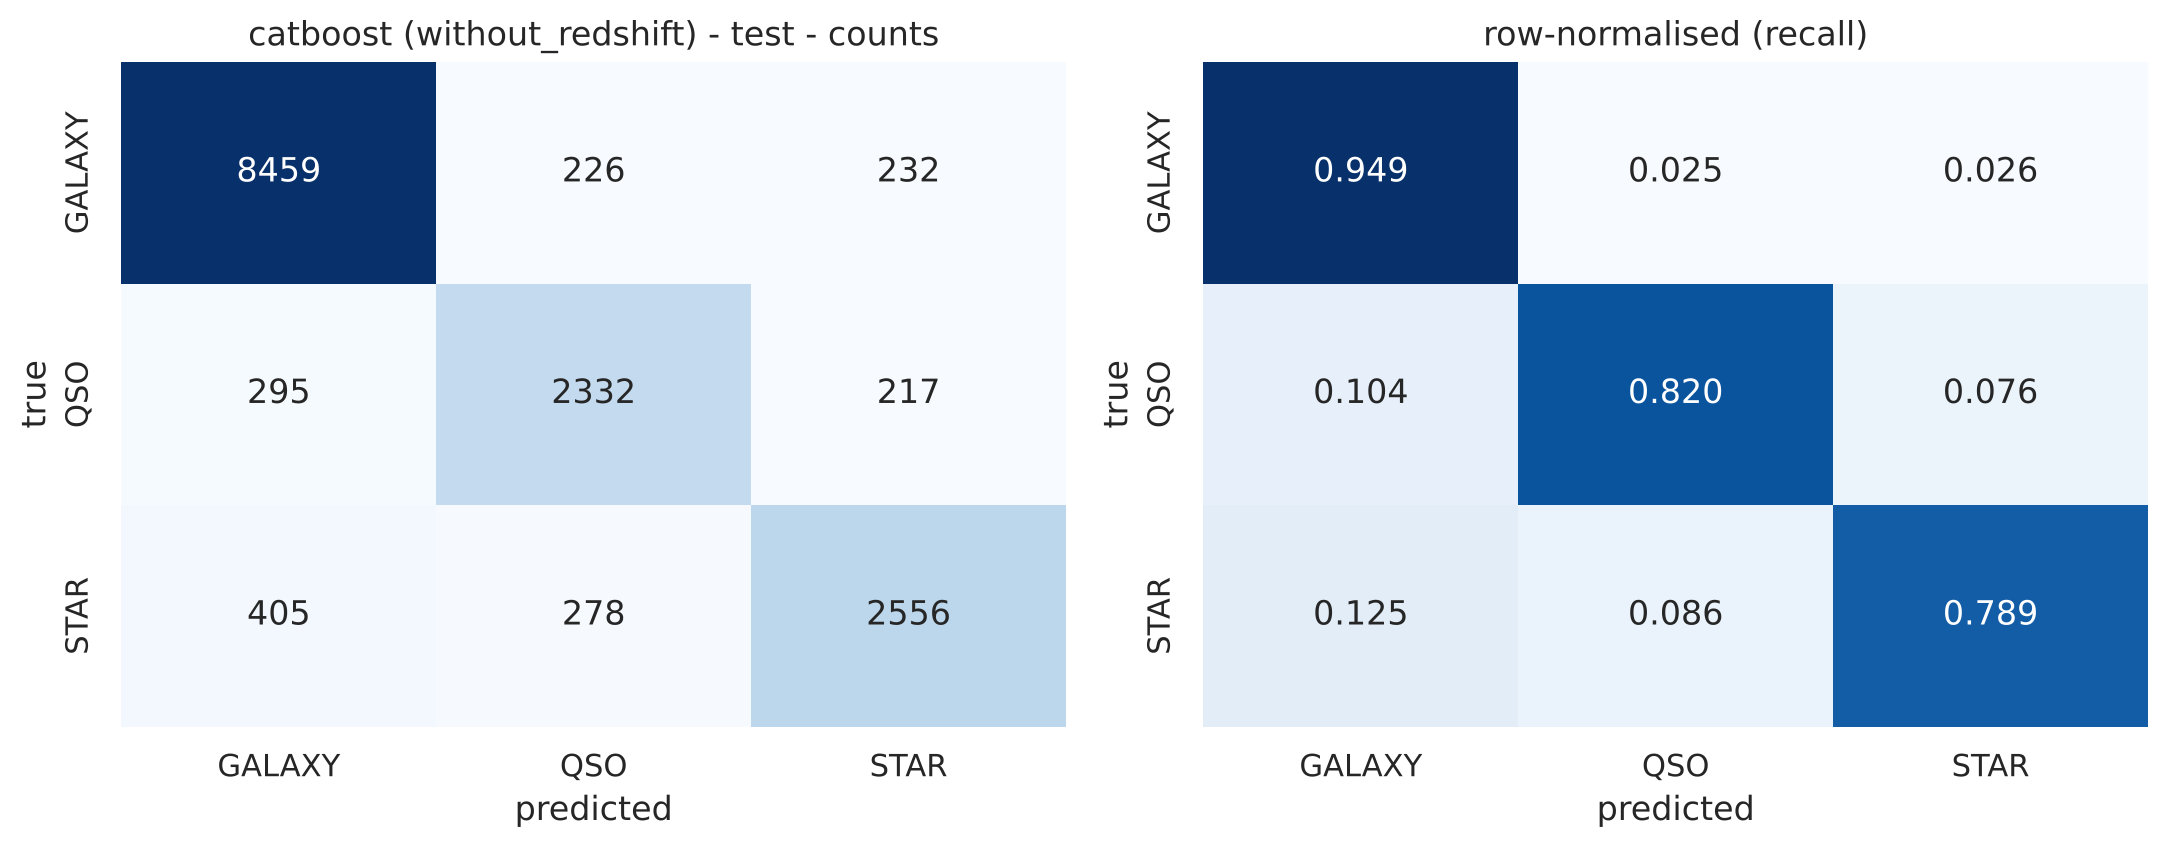

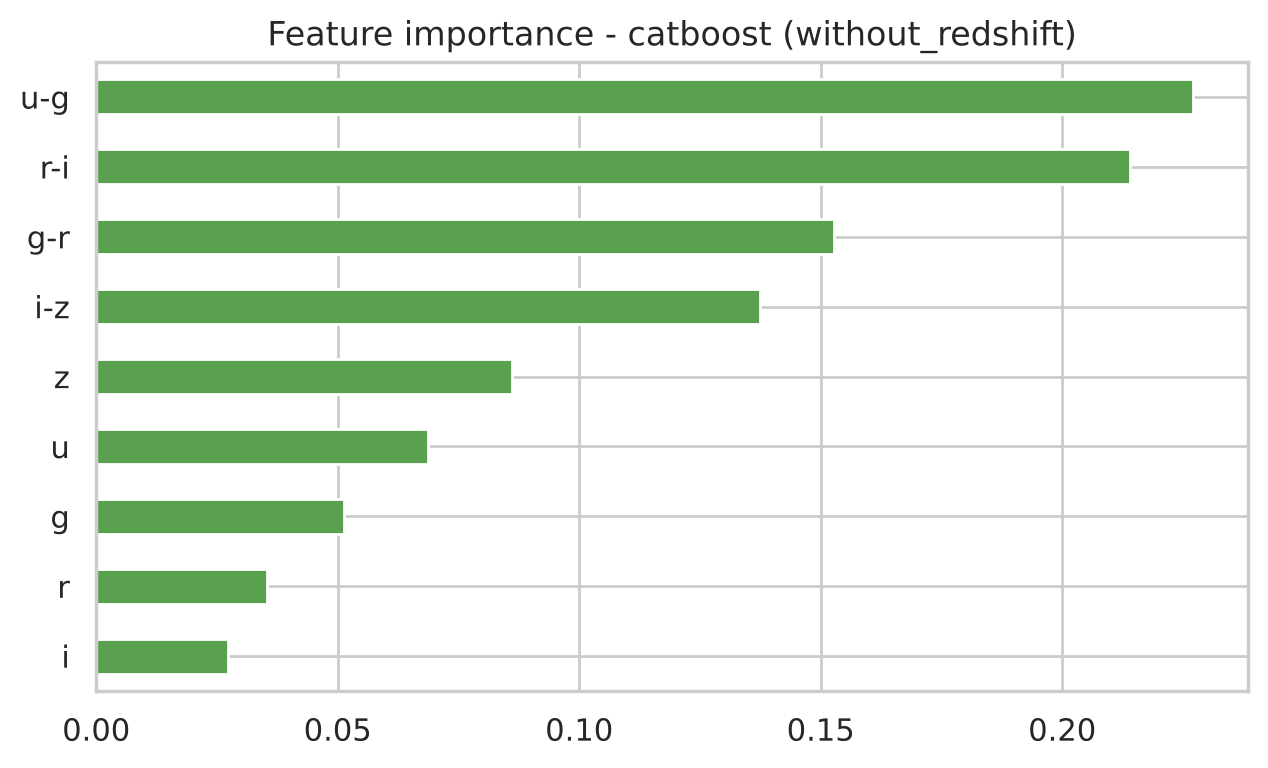


test: {'accuracy': 0.8898, 'macro_f1': 0.8586, 'weighted_f1': 0.8889}


,with redshift,without redshift
accuracy,0.9782,0.8898
macro_f1,0.9749,0.8586
weighted_f1,0.9781,0.8889
precision_macro,0.9765,0.8655
recall_macro,0.9734,0.8526
precision_weighted,0.9781,0.8886
recall_weighted,0.9782,0.8898
f1_GALAXY,0.9818,0.9359
f1_QSO,0.9513,0.8211
f1_STAR,0.9915,0.8187


In [8]:
res_nz = run_experiment("without_redshift", N_TRIALS_NOZ)
print()
print("test:", {k: round(v, 4) for k, v in res_nz["test"].items() if k in ("accuracy", "macro_f1", "weighted_f1")})
display(pd.DataFrame({"with redshift": {k: v for k, v in res_z["test"].items()}, "without redshift": res_nz["test"]}).round(4))

**Reading:** removing `redshift` costs roughly 12 points of Macro-F1, and the loss falls on the **QSO and STAR** classes (look at the per-class F1 rows): in photometry alone quasars blend with stars and galaxies, and redshift is what pulls them apart. The comparison of both algorithms and the final choice follow in notebook 05.

## 8. Summary table of this notebook

In [9]:
display(pd.DataFrame({
    "config": ["with_redshift", "without_redshift"],
    "trials": [res_z["n_trials"], res_nz["n_trials"]],
    "best val Macro-F1 (Optuna)": [res_z["optuna_best_val_macro_f1"], res_nz["optuna_best_val_macro_f1"]],
    "test Macro-F1": [res_z["test"]["macro_f1"], res_nz["test"]["macro_f1"]],
    "test accuracy": [res_z["test"]["accuracy"], res_nz["test"]["accuracy"]],
    "trees used": [res_z["best_iteration"], res_nz["best_iteration"]],
    "Optuna time (s)": [round(res_z["optuna_seconds"]), round(res_nz["optuna_seconds"])],
}).round(4))
print("Next: 04_LightGBM... (same protocol), then 05 for the comparison and the final model.")

,config,trials,best val Macro-F1 (Optuna),test Macro-F1,test accuracy,trees used,Optuna time (s)
0,with_redshift,20,0.9742,0.9749,0.9782,620,676
1,without_redshift,10,0.8518,0.8586,0.8898,219,247


Next: 04_LightGBM... (same protocol), then 05 for the comparison and the final model.
